In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import LinearSVR, SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
!pip install catboost
from catboost import CatBoostRegressor

import warnings
warnings.filterwarnings(action='ignore')

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 MB 9.8 MB/s eta 0:00:00


In [3]:
data = pd.read_csv('/content/drive/MyDrive/Final year project/Vegetable_market.csv')

In [8]:
data.head(100)

,Vegetable,Season,Month,Temp,Deasaster Happen in last 3month,Vegetable condition,Price per kg
0,potato,winter,jan,15,no,fresh,20
1,tomato,winter,jan,15,no,fresh,50
2,peas,winter,jan,15,no,fresh,70
3,pumkin,winter,jan,15,no,fresh,25
4,cucumber,winter,jan,15,no,fresh,20
...,...,...,...,...,...,...,...
95,califlower,summer,apr,37,no,fresh,55
96,pointed grourd,monsoon,july,30,no,fresh,30
97,potato,monsoon,aug,31,yes,fresh,45
98,peas,monsoon,july,30,yes,fresh,170


In [5]:
data.info

<bound method DataFrame.info of     Vegetable  Season Month  Temp Deasaster Happen in last 3month  \
0      potato  winter   jan    15                              no   
1     tomato   winter   jan    15                              no   
2        peas  winter   jan    15                              no   
3      pumkin  winter   jan    15                              no   
4    cucumber  winter   jan    15                              no   
..        ...     ...   ...   ...                             ...   
116   brinjal  winter   jan    15                             yes   
117    ginger  winter   jan    15                              no   
118    potato  summer   apr    32                              no   
119      peas  summer   apr    33                              no   
120    radish  summer   apr    32                              no   

    Vegetable condition  Price per kg  
0                 fresh            20  
1                 fresh            50  
2                 f

In [13]:
def preprocess_inputs(df):
    df = df.copy()
    
    # Clean Vegetable condition column
    df['Vegetable condition'] = df['Vegetable condition'].replace({'scarp': 'scrap'})
    
    # Binary encoding
    df['Deasaster Happen in last 3month'] = df['Deasaster Happen in last 3month'].replace({'no': 0, 'yes': 1})
    
    # Ordinal encoding
    df['Month'] = df['Month'].replace({
        'jan': 1,
        'apr': 4,
        'july': 7,
        'sept': 9,
        'oct': 10,
        'dec': 12,
        'may': 5,
        'aug': 8,
        'june': 6,
        ' ': np.NaN,
        'march': 3
    })
    
    # Fill missing month values with column mode
    df['Month'] = df['Month'].fillna(df['Month'].mode()[0])
    
    # One-hot encoding
    #for column in ['Vegetable', 'Season', 'Vegetable condition']:
     #   df = onehot_encode(df, column)
    
    #label encoding
    from sklearn.preprocessing import LabelEncoder
    var = LabelEncoder()
    df['Vegetable']=var.fit_transform(df['Vegetable']) 
    df['Season']=var.fit_transform(df['Season']) 
    df['Vegetable condition']=var.fit_transform(df['Vegetable condition']) 

    # Split df into X and y
    y = df['Price per kg']
    X = df.drop('Price per kg', axis=1)
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.9, shuffle=True, random_state=1)
    
    # Scale X
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X_train.columns)
    X_test = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)
    
    return X_train, X_test, y_train, y_test


In [14]:
X_train, X_test, y_train, y_test = preprocess_inputs(data)

In [17]:
models = {
    "                     Linear Regression": LinearRegression(),
    " Linear Regression (L2 Regularization)": Ridge(),
    " Linear Regression (L1 Regularization)": Lasso(),
    "                   K-Nearest Neighbors": KNeighborsRegressor(),
    "                         Decision Tree": DecisionTreeRegressor(),
    "                         Random Forest": RandomForestRegressor(),
    "                     Gradient Boosting": GradientBoostingRegressor(),
    "                               XGBoost": XGBRegressor(),
    "                              LightGBM": LGBMRegressor(),
    "                              CatBoost": CatBoostRegressor(verbose=0)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name + " trained.")

                     Linear Regression trained.
 Linear Regression (L2 Regularization) trained.
 Linear Regression (L1 Regularization) trained.
                   K-Nearest Neighbors trained.
                         Decision Tree trained.
                         Random Forest trained.
                     Gradient Boosting trained.
                               XGBoost trained.
                              LightGBM trained.
                              CatBoost trained.


In [18]:
for name, model in models.items():
    print(name + " R^2 Score: {:.5f}".format(model.score(X_test, y_test)))
    

                     Linear Regression R^2 Score: 0.20375
 Linear Regression (L2 Regularization) R^2 Score: 0.20226
 Linear Regression (L1 Regularization) R^2 Score: 0.20335
                   K-Nearest Neighbors R^2 Score: 0.50347
                         Decision Tree R^2 Score: 0.76203
                         Random Forest R^2 Score: 0.81794
                     Gradient Boosting R^2 Score: 0.81569
                               XGBoost R^2 Score: 0.76115
                              LightGBM R^2 Score: 0.74761
                              CatBoost R^2 Score: 0.77284


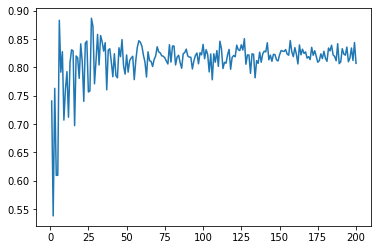

In [31]:
a=[]
for i in range(1,201):
 model=RandomForestRegressor(n_estimators=i)
 model.fit(X_train, y_train)
 accuracy = model.score(X_test, y_test)
 a.append(accuracy)

from matplotlib import pyplot as plt
%matplotlib inline
plt.plot(range(1,201), a)
plt.show()

In [34]:
a[26]

0.8865701257238672

In [ ]:
data

,Vegetable,Season,Month,Temp,Deasaster Happen in last 3month,Vegetable condition,Price per kg
0,potato,winter,jan,15,no,fresh,20
1,tomato,winter,jan,15,no,fresh,50
2,peas,winter,jan,15,no,fresh,70
3,pumkin,winter,jan,15,no,fresh,25
4,cucumber,winter,jan,15,no,fresh,20
...,...,...,...,...,...,...,...
116,brinjal,winter,jan,15,yes,fresh,33
117,ginger,winter,jan,15,no,fresh,88
118,potato,summer,apr,32,no,fresh,24
119,peas,summer,apr,33,no,fresh,33


In [ ]:
crop_names_unique=data.Vegetable.unique()
print(len(crop_names_unique))
a=list(crop_names_unique)
a.sort()
for i in range(0,len(a)):
  print(a[i])

17
Bitter gourd
Raddish
brinjal
cabage
califlower
chilly
cucumber
garlic
ginger
okra
onion
peas
pointed grourd 
potato
pumkin
radish
tomato 
